# When AI Stocks Are the Market: Managing AI-Driven Concentration Risk and Hedging Its Tail

The ten largest US stocks — mostly AI leaders — now carry about 40% of the S&P 500's
weight. Prior research says concentration does not predict returns, so investors should
"do nothing". This notebook tests whether concentration still changes a portfolio's
**tail risk**, compares ways to manage the concentration, and asks which hedge protects
a concentrated portfolio best **after costs**.

**Author:** Kavin Dhanasekaran — MS Financial Engineering, NYU Tandon. Research only, not investment advice.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, data_loaders as dl

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
np.random.seed(config.RANDOM_SEED)

## 1. Load and cache data

Download (or load from cache) every series the project needs and print each one's date
range as a sanity check. Raw files are cached under `data/raw/`, processed series under
`data/processed/`; nothing re-downloads unless `force=True`.

In [2]:
industries = dl.load_industry_portfolios()
ff_factors = dl.load_ff_factors()
candidate_prices = dl.load_prices(config.CANDIDATE_TICKERS, "candidates", start="2009-01-01")
index_prices = dl.load_prices(config.INDEX_TICKERS, "index", start="2009-01-01")
vix = dl.load_vix_term_structure()
pput = dl.load_pput()
rf_daily = dl.load_risk_free_daily()
shares = dl.load_shares_outstanding(config.CANDIDATE_TICKERS)

In [3]:
def _range_row(name, obj):
    idx = obj.index
    cols = obj.shape[1] if hasattr(obj, "shape") and obj.ndim == 2 else 1
    return {"series": name, "start": idx.min().date(), "end": idx.max().date(),
            "rows": len(idx), "cols": cols}

sanity = pd.DataFrame([
    _range_row("49 industry returns (monthly)", industries["returns"]),
    _range_row("Fama-French factors (monthly)", ff_factors),
    _range_row("candidate mega-cap prices (daily)", candidate_prices),
    _range_row("index & hedge prices (daily)", index_prices),
    _range_row("VIX term structure (daily)", vix),
    _range_row("PPUT benchmark (daily)", pput.to_frame()),
    _range_row("risk-free DTB3 (daily)", rf_daily.to_frame()),
    _range_row("shares outstanding (EDGAR)", shares),
])
sanity.set_index("series")

,start,end,rows,cols
series,,,,
49 industry returns (monthly),1926-07-31,2026-08-31,1202,49
Fama-French factors (monthly),1926-07-31,2026-08-31,1202,5
candidate mega-cap prices (daily),2009-01-02,2026-10-13,4472,32
index & hedge prices (daily),2009-01-02,2026-10-13,4472,4
VIX term structure (daily),1990-01-02,2026-10-13,9265,5
PPUT benchmark (daily),1986-06-30,2026-10-12,10144,1
risk-free DTB3 (daily),1954-01-04,2026-10-08,18184,1
shares outstanding (EDGAR),2009-01-31,2026-09-07,1095,32


## 2. Replication of Kritzman & Turkington (2025)

We rebuild a simplified market-concentration series — the effective number of
industries, `1 / Σ wᵢ²` on the 49 value-weighted industry caps — then test whether it
predicts future returns, volatility or drawdowns (Newey-West errors), and run their
concentration-timing rule against buy-and-hold.

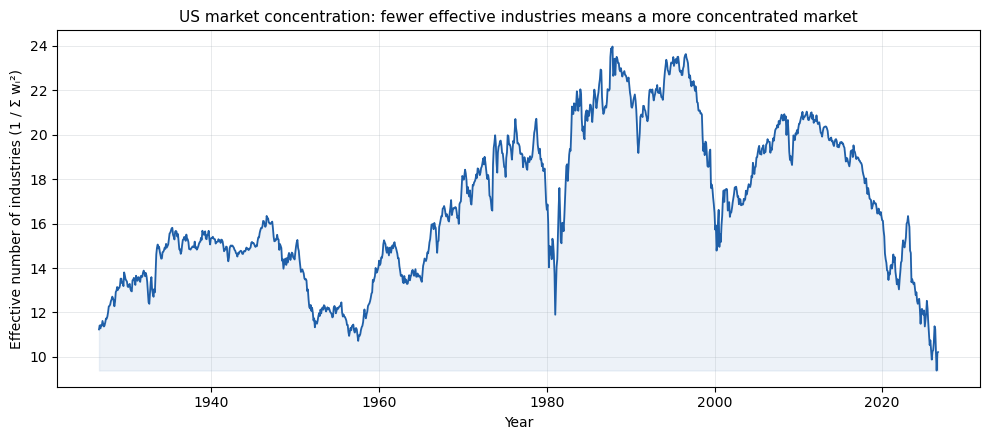

Effective industries: min 9.4, max 24.0, latest 10.2


In [4]:
from src import replication as rep, plots

weights = rep.industry_weights(industries["n_firms"], industries["avg_size"])
concentration = rep.effective_number(weights)
plots.plot_concentration_over_time(concentration)
plt.show()
print(f"Effective industries: min {concentration.min():.1f}, "
      f"max {concentration.max():.1f}, latest {concentration.dropna().iloc[-1]:.1f}")

In [5]:
predictive = rep.run_predictive_table(concentration, ff_factors)
predictive.to_csv(config.TABLES_DIR / "replication_predictive.csv")
predictive

,coef,t_stat,r_squared,n_obs
excess_return_1m,-0.0013,-0.8401,0.0006,"1,201.0000"
excess_return_3m,-0.0044,-1.0688,0.0020,"1,199.0000"
excess_return_12m,-0.0101,-0.6276,0.0024,"1,190.0000"
realised_vol_12m,-0.0125,-1.3997,0.0193,"1,190.0000"
max_drawdown_12m,0.0102,1.1151,0.0102,"1,190.0000"


In [6]:
timing = rep.concentration_timing_backtest(concentration, ff_factors)
timing.to_csv(config.TABLES_DIR / "replication_timing.csv")
timing

,ann_return,ann_vol,sharpe,max_drawdown
timing,0.0959,0.1793,0.4205,-0.8365
buy_and_hold,0.1038,0.1833,0.4545,-0.8365
